# Previsão de Produtividade Municipal da Soja no RS — Modelagem (Etapa 3: correção da tendência)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** a Etapa 2 (`modelagem_etapa2.ipynb`) mostrou que o clima por subperíodo explica ~40% da variação do rendimento, mas que as previsões de 2021–2025 ficaram enviesadas para cima porque a tendência (reta ajustada até 2020) projetava um patamar de produtividade muito acima do observado. Este notebook compara quatro formas de calcular o **patamar esperado** de cada município — reta estadual com todo o histórico, média móvel dos últimos 5 anos, média olímpica dos últimos 5 anos e reta dos últimos 10 anos —, todas usando **só safras anteriores** à prevista. Para cada patamar, o clima (lido de `dataset/processed/clima_subperiodos_estacao_safra.csv`) prevê o desvio em relação a ele, com uma OLS reduzida (uma variável por fenômeno, para coeficientes interpretáveis) e com Gradient Boosting. Avalia com o corte temporal (teste 2021–2025) e com "deixa uma safra de fora", compara com as duas linhas de base da metodologia do artigo (média histórica e safra anterior) e define o modelo final. Para o modelo final, decompõe cada previsão na contribuição de cada fator climático (equivalente ao SHAP para modelo linear) e calcula o erro por mesorregião do IBGE e por município.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-22 |                 | Criação do notebook — comparação de patamares (tendência), OLS reduzida e Gradient Boosting sobre o desvio, duas validações e escolha do modelo final |
| 2026-10-22 |                 | Linhas de base do artigo (média histórica, safra anterior), contribuição por variável (SHAP do modelo linear), erro por mesorregião e por município |

## 1. Imports e configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020      # corte temporal: modelos de clima treinados até 2020, teste 2021-2025
PRIMEIRA_SAFRA = 2005 # a partir daqui todo patamar tem pelo menos 5 safras anteriores
SEED = 42

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Dados

- Painel município–safra (rendimento, estação INMET associada, clima agregado e ONI);
- Clima por subperíodo por estação e safra, gerado na Etapa 2.

In [2]:
painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
clima_sub = pd.read_csv(f"{PROCESSED}/clima_subperiodos_estacao_safra.csv")

ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]

com_rendimento = painel.dropna(subset=[ALVO])
print(f"Linhas com rendimento: {len(com_rendimento)} | estação × safra com clima: {len(clima_sub)}")

Linhas com rendimento: 10540 | estação × safra com clima: 1125


## 3. Quatro formas de calcular o patamar esperado

O **patamar** é o rendimento que se espera do município numa safra "normal", antes de
olhar o clima. Para a safra *Y*, todas as versões usam **só o rendimento observado nas
safras anteriores a Y** — exatamente a informação disponível em março do ano *Y* (o IBGE
publica o rendimento de uma safra por volta de setembro do mesmo ano).

| Patamar | Como é calculado | Ideia |
|---|---|---|
| **Reta estadual (histórico todo)** | reta ajustada às médias estaduais de 2000 até Y−1, projetada para Y, + diferença média do município em relação ao estado | É a abordagem da Etapa 2, agora atualizada a cada safra |
| **Média móvel 5 anos** | média do rendimento do município em Y−5 … Y−1 | Acompanha o patamar recente, sem extrapolar |
| **Média olímpica 5 anos** | média de Y−5 … Y−1 descartando o melhor e o pior ano | Usada em seguro agrícola: um ano de seca ou recorde isolado não distorce o patamar |
| **Reta dos últimos 10 anos** | reta das médias estaduais de Y−10 … Y−1 projetada para Y, + diferença média do município nesses anos | Tendência, mas que se adapta a mudanças recentes |

Regras: o município precisa de pelo menos 3 safras com rendimento na janela (5 para a
média olímpica descartar extremos; com 3 ou 4, usa a média simples). Sem isso, usa o
valor equivalente calculado com as médias do estado. A média estadual é a média simples
dos municípios com rendimento em cada safra.

Também são calculadas as **duas linhas de base previstas na metodologia do artigo**,
usadas como régua (sem clima):

- **Média histórica** — média do rendimento do município em todas as safras anteriores
  (mínimo de 3; senão, média estadual das safras anteriores);
- **Safra anterior** — rendimento do município na safra Y−1 (sem dado, usa a média
  estadual de Y−1).

In [3]:
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio",
                                  values=ALVO)
estado = rend.mean(axis=1)


def media_olimpica(janela, n):
    # descarta o maior e o menor valor quando há pelo menos 5 safras; senão, média simples
    olimpica = (janela.sum() - janela.max() - janela.min()) / (n - 2)
    return olimpica.where(n >= 5, janela.mean())


def reta_projetada(serie, ano):
    coef = np.polyfit(serie.index, serie.to_numpy(), 1)
    return np.polyval(coef, ano)


def diferenca_municipio(janela):
    dif = janela.sub(estado.loc[janela.index], axis=0)
    return dif.mean().where(dif.count() >= 3, 0.0)


partes = []
for ano in range(PRIMEIRA_SAFRA, int(rend.index.max()) + 1):
    j5 = rend.loc[ano - 5:ano - 1]
    n5 = j5.count()
    e5 = estado.loc[ano - 5:ano - 1]
    j10 = rend.loc[ano - 10:ano - 1]
    todos = rend.loc[:ano - 1]
    partes.append(pd.DataFrame({
        "ano_safra": ano,
        "patamar_reta": reta_projetada(estado.loc[:ano - 1], ano) + diferenca_municipio(todos),
        "patamar_mm5": j5.mean().where(n5 >= 3, e5.mean()),
        "patamar_olimpica5": media_olimpica(j5, n5).where(n5 >= 3, (e5.sum() - e5.max() - e5.min()) / 3),
        "patamar_reta10": reta_projetada(estado.loc[ano - 10:ano - 1], ano) + diferenca_municipio(j10),
        "base_media_hist": todos.mean().where(todos.count() >= 3, estado.loc[:ano - 1].mean()),
        "base_safra_anterior": rend.loc[ano - 1].fillna(estado.loc[ano - 1]),
    }))
patamares = (pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index())

PATAMARES = {"patamar_reta": "Reta estadual (histórico todo)",
             "patamar_mm5": "Média móvel 5 anos",
             "patamar_olimpica5": "Média olímpica 5 anos",
             "patamar_reta10": "Reta dos últimos 10 anos"}
LINHAS_BASE = {"base_media_hist": "Linha de base: média histórica",
               "base_safra_anterior": "Linha de base: safra anterior"}
NOMES = {**PATAMARES, **LINHAS_BASE}
print(f"Patamares calculados: {len(patamares)} linhas (município × safra, {PRIMEIRA_SAFRA}–{int(rend.index.max())})")

Patamares calculados: 9534 linhas (município × safra, 2005–2025)


### Patamar estadual × rendimento observado

Antes de qualquer clima: como cada patamar se compara ao rendimento médio do estado? O
patamar ideal acompanha o nível "normal" da produtividade sem tentar prever secas — as
quedas abaixo dele são o que o clima deve explicar.

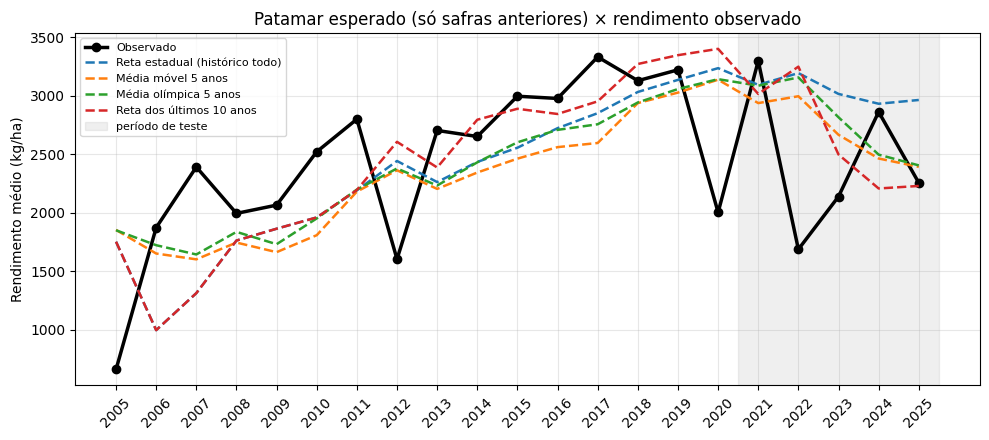

,rendimento_kg_ha,patamar_reta,patamar_mm5,patamar_olimpica5,patamar_reta10
ano_safra,,,,,
2018,"3,128.00","3,032.00","2,937.00","2,942.00","3,271.00"
2019,"3,221.00","3,135.00","3,027.00","3,057.00","3,346.00"
2020,"2,003.00","3,235.00","3,137.00","3,141.00","3,400.00"
2021,"3,297.00","3,093.00","2,937.00","3,086.00","3,015.00"
2022,"1,688.00","3,193.00","2,996.00","3,156.00","3,248.00"
2023,"2,139.00","3,015.00","2,666.00","2,816.00","2,498.00"
2024,"2,862.00","2,931.00","2,464.00","2,497.00","2,208.00"
2025,"2,256.00","2,964.00","2,392.00","2,405.00","2,229.00"


In [4]:
pat_estado = (patamares.merge(com_rendimento[["codigo_ibge_municipio", "ano_safra", ALVO]],
                              on=["codigo_ibge_municipio", "ano_safra"])
              .groupby("ano_safra")[[ALVO] + list(PATAMARES)].mean())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pat_estado.index, pat_estado[ALVO], "k-o", lw=2.5, label="Observado")
for col, nome in PATAMARES.items():
    ax.plot(pat_estado.index, pat_estado[col], "--", lw=1.8, label=nome)
ax.axvspan(ANO_CORTE + 0.5, pat_estado.index.max() + 0.5, color="grey", alpha=0.12,
           label="período de teste")
ax.set_xticks(pat_estado.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Rendimento médio (kg/ha)")
ax.set_title("Patamar esperado (só safras anteriores) × rendimento observado")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
pat_estado.loc[2018:].round(0)

## 4. Base de modelagem

Linhas com rendimento, patamares e todas as variáveis climáticas, a partir de 2005.

In [5]:
base = (painel.merge(clima_sub, on=["codigo_estacao", "ano_safra"], how="left")
        .merge(patamares, on=["codigo_ibge_municipio", "ano_safra"], how="left"))
base = base.dropna(subset=[ALVO, ONI] + CLIMA + list(NOMES)).copy()
base = base[base["ano_safra"] >= PRIMEIRA_SAFRA]
print(f"Linhas: {len(base)} | municípios: {base['codigo_ibge_municipio'].nunique()} | "
      f"safras: {base['ano_safra'].min()}–{base['ano_safra'].max()}")
print(f"  treino (<= {ANO_CORTE}): {(base['ano_safra'] <= ANO_CORTE).sum()} | "
      f"teste (> {ANO_CORTE}): {(base['ano_safra'] > ANO_CORTE).sum()}")

Linhas: 5260 | municípios: 448 | safras: 2005–2025
  treino (<= 2020): 3669 | teste (> 2020): 1591


## 5. Modelos

Para cada patamar, três previsões:

1. **Só patamar** — sem clima. Mede quão bom é o patamar sozinho.
2. **Patamar + OLS reduzida** — a OLS prevê o desvio (rendimento − patamar) com **uma
   variável por fenômeno**, para eliminar a colinearidade que gerou sinais sem sentido
   na Etapa 2 (temperatura máxima positiva, ONI negativo):
   - `chuva_out_nov` — chuva na semeadura;
   - `chuva_dez_fev` e seu quadrado — chuva no período crítico, com ganho decrescente;
   - `chuva_mar` — chuva no fim do enchimento;
   - `dias_calor_dez_fev` — estresse térmico (no lugar da temperatura máxima média);
   - `urmin_dez_fev` — secura do ar (no lugar da sequência seca, que perdeu
     significância na Etapa 2).
   O ONI fica de fora: o efeito do El Niño já chega ao modelo pela chuva e pela umidade.
3. **Patamar + Gradient Boosting** — prevê o desvio com todas as variáveis climáticas e
   o ONI.

Previsão final = patamar + desvio previsto.

As duas linhas de base (média histórica e safra anterior) entram nas tabelas como
previsões sem clima, para comparação.

In [6]:
FEAT_OLS = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
            "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_GB = CLIMA + [ONI]


def derivar(d, media_dez_fev):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - media_dez_fev) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    return d


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


def prever_todos(tr, te):
    # Devolve {(patamar, modelo): previsão} para todas as combinações
    media = tr["chuva_dez_fev"].mean()
    tr, te = derivar(tr, media), derivar(te, media)
    saida = {(col, "Sem clima"): te[col].to_numpy() for col in LINHAS_BASE}
    for pat in PATAMARES:
        desvio = tr[ALVO] - tr[pat]
        saida[(pat, "Só patamar")] = te[pat].to_numpy()
        ols = LinearRegression().fit(tr[FEAT_OLS], desvio)
        saida[(pat, "+ OLS reduzida")] = te[pat].to_numpy() + ols.predict(te[FEAT_OLS])
        modelo_gb = gb().fit(tr[FEAT_GB], desvio)
        saida[(pat, "+ Gradient Boosting")] = te[pat].to_numpy() + modelo_gb.predict(te[FEAT_GB])
    return saida


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}


def tabela(y, previsoes):
    t = pd.DataFrame({k: metricas(y, p) for k, p in previsoes.items()}).T
    t.index = pd.MultiIndex.from_tuples([(NOMES[p], m) for p, m in t.index],
                                        names=["patamar", "modelo"])
    return t


FORMATO = {"RMSE (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}", "R²": "{:.3f}",
           "Viés (kg/ha)": "{:+.0f}"}
print("Combinações:", len(PATAMARES) * 3 + len(LINHAS_BASE))

Combinações: 14


## 6. Validação 1 — corte temporal (treino até 2020, teste 2021–2025)

O modelo de clima é treinado só até 2020. O patamar de cada safra de teste usa as safras
anteriores a ela (por exemplo, o patamar de 2023 já conhece o rendimento de 2021 e 2022),
como aconteceria na prática.

Referência da Etapa 2 neste mesmo teste (base um pouco diferente): melhor modelo com
RMSE ≈ 815 kg/ha, R² ≈ 0,15 e viés de +216 kg/ha; o Gradient Boosting teve RMSE ≈ 1.015
e viés de +717 kg/ha.

In [7]:
treino = base[base["ano_safra"] <= ANO_CORTE]
teste = base[base["ano_safra"] > ANO_CORTE]
prev_corte = prever_todos(treino, teste)
corte = tabela(teste[ALVO], prev_corte)
print(f"Teste: {len(teste)} linhas | rendimento médio {teste[ALVO].mean():.0f} kg/ha")
corte.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

Teste: 1591 linhas | rendimento médio 2497 kg/ha


## 7. Validação 2 — deixa uma safra de fora (2008–2025)

O modelo de clima de cada rodada é treinado com todas as outras safras. O patamar
continua usando só safras anteriores (não depende da validação).

Referência da Etapa 2: melhor modelo com RMSE ≈ 591 kg/ha e R² ≈ 0,44. **Atenção:** esse
número não é diretamente comparável e era otimista. Na Etapa 2, a tendência e o efeito
do município de cada rodada eram calculados com todas as outras safras, **inclusive as
posteriores** à safra prevista — para prever 2012, o modelo já "conhecia" o patamar de
2013–2025, informação que nunca está disponível na prática. Aqui o patamar usa só o
passado, então os valores abaixo são a medida realista.

In [8]:
anos_loyo = [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]
partes = []
for ano in anos_loyo:
    tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
    p = prever_todos(tr, te)
    partes.append(te[["codigo_ibge_municipio", "ano_safra", ALVO]]
                  .assign(**{f"{a}|{b}": v for (a, b), v in p.items()}))
loyo = pd.concat(partes, ignore_index=True)
prev_loyo = {tuple(c.split("|")): loyo[c].to_numpy() for c in loyo.columns if "|" in c}
geral = tabela(loyo[ALVO], prev_loyo)
print(f"{len(anos_loyo)} safras, {len(loyo)} linhas")
geral.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

18 safras, 5125 linhas


## 8. Resumo lado a lado e escolha do modelo final

O modelo final deve ser bom **nas duas validações**: no corte temporal (simula a
previsão real nas safras mais recentes) e no "deixa uma safra de fora" (estabilidade
entre safras). O critério é a média do RMSE nas duas.

In [9]:
resumo = pd.concat({"Corte 2021–2025": corte[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
                    "Deixa uma safra de fora": geral[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]]},
                   axis=1)
resumo[("Média", "RMSE (kg/ha)")] = (resumo[("Corte 2021–2025", "RMSE (kg/ha)")]
                                     + resumo[("Deixa uma safra de fora", "RMSE (kg/ha)")]) / 2
resumo = resumo.sort_values(("Média", "RMSE (kg/ha)"))
FINAL = resumo.index[0]
print("Modelo final (menor RMSE médio):", " ".join(FINAL))
resumo.style.format("{:.0f}").format("{:.3f}", subset=[c for c in resumo.columns if c[1] == "R²"])

Modelo final (menor RMSE médio): Média móvel 5 anos + OLS reduzida


## 9. Modelo final — safra a safra

Rendimento médio do estado por safra: observado × previsto pelo modelo final, nas duas
validações, com a previsão "só patamar" do mesmo patamar para mostrar quanto o clima
acrescenta.

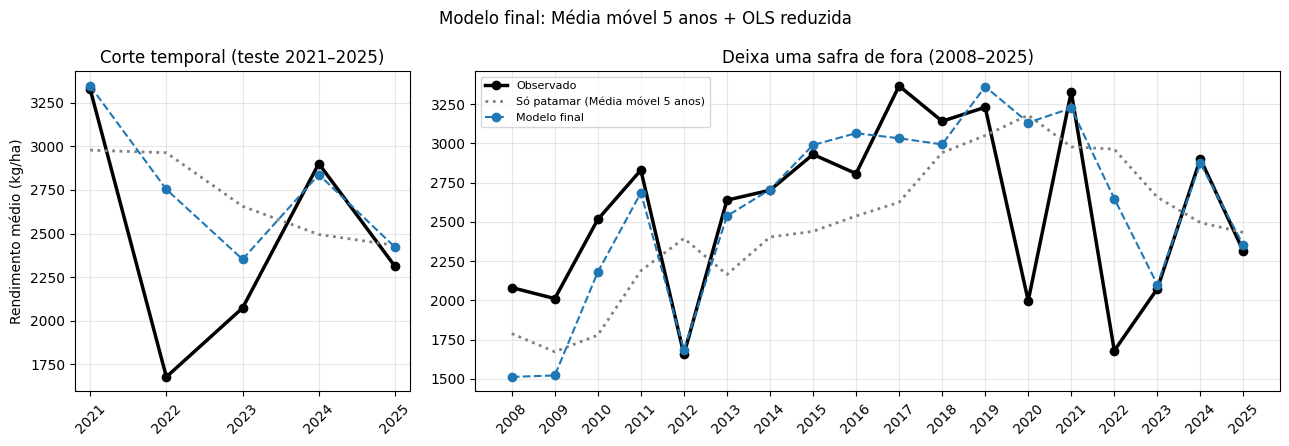

,MAE da média estadual (kg/ha),correlação com o observado
Corte 2021–2025,308.70,0.72
Deixa uma safra de fora,272.42,0.71


,rendimento_kg_ha,final,patamar
ano_safra,,,
2021,"3,328.00","3,346.00","2,978.00"
2022,"1,679.00","2,753.00","2,963.00"
2023,"2,074.00","2,352.00","2,656.00"
2024,"2,900.00","2,837.00","2,494.00"
2025,"2,312.00","2,422.00","2,432.00"


In [10]:
pat_final = {v: k for k, v in NOMES.items()}[FINAL[0]]
chave_final, chave_pat = (pat_final, FINAL[1]), (pat_final, "Só patamar")

estado_corte = (teste[["ano_safra", ALVO]]
                .assign(final=prev_corte[chave_final], patamar=prev_corte[chave_pat])
                .groupby("ano_safra").mean())
estado_loyo = (loyo[["ano_safra", ALVO]]
               .assign(final=prev_loyo[chave_final], patamar=prev_loyo[chave_pat])
               .groupby("ano_safra").mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.4]})
for ax, dados, titulo in [(axes[0], estado_corte, "Corte temporal (teste 2021–2025)"),
                          (axes[1], estado_loyo, "Deixa uma safra de fora (2008–2025)")]:
    ax.plot(dados.index, dados[ALVO], "k-o", lw=2.5, label="Observado")
    ax.plot(dados.index, dados["patamar"], ":", color="grey", lw=2, label=f"Só patamar ({FINAL[0]})")
    ax.plot(dados.index, dados["final"], "--o", color="tab:blue", label="Modelo final")
    ax.set_xticks(dados.index)
    ax.tick_params(axis="x", rotation=45)
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Rendimento médio (kg/ha)")
axes[1].legend(fontsize=8)
fig.suptitle(f"Modelo final: {' '.join(FINAL)}")
plt.tight_layout()
plt.show()

erro_estado = pd.DataFrame({
    "MAE da média estadual (kg/ha)": [(estado_corte["final"] - estado_corte[ALVO]).abs().mean(),
                                      (estado_loyo["final"] - estado_loyo[ALVO]).abs().mean()],
    "correlação com o observado": [estado_corte["final"].corr(estado_corte[ALVO]),
                                   estado_loyo["final"].corr(estado_loyo[ALVO])]},
    index=["Corte 2021–2025", "Deixa uma safra de fora"])
display(erro_estado.round(2))
estado_corte.round(0)

## 10. Coeficientes da OLS reduzida

Ajustada com todas as safras da base (2005–2025) sobre o desvio em relação ao patamar
final. Com uma variável por fenômeno, os sinais devem ser coerentes com a agronomia.
Mesma ressalva das etapas anteriores: os p-valores tendem a ser otimistas porque linhas
da mesma safra são correlacionadas.

In [11]:
def tabela_ols(modelo, X, y):
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    ep = np.sqrt(np.diag(residuos @ residuos / gl * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


completa = derivar(base, base["chuva_dez_fev"].mean())
desvio_final = completa[ALVO] - completa[pat_final]
ols_final = LinearRegression().fit(completa[FEAT_OLS], desvio_final)
print(f"Patamar: {FINAL[0]} | chuva média de dez–fev: {base['chuva_dez_fev'].mean():.0f} mm")
print("Correlação entre as variáveis da OLS reduzida (maior |r| fora da diagonal):",
      f"{completa[FEAT_OLS].drop(columns='chuva_dez_fev_c100_2').corr().abs().where(lambda m: m < 1).max().max():.2f}")
tabela_ols(ols_final, completa[FEAT_OLS], desvio_final)

Patamar: Média móvel 5 anos | chuva média de dez–fev: 417 mm
Correlação entre as variáveis da OLS reduzida (maior |r| fora da diagonal): 0.63


,coeficiente,erro_padrao,t,p_valor
intercepto,"-1,223.11",98.19,-12.46,0.00
chuva_out_nov_100,-2.85,4.98,-0.57,0.57
chuva_dez_fev_c100,207.74,7.72,26.90,0.00
chuva_dez_fev_c100_2,-41.25,2.45,-16.81,0.00
chuva_mar_100,59.38,12.00,4.95,0.00
dias_calor_dez_fev,-2.69,0.71,-3.77,0.00
urmin_dez_fev,29.89,1.87,16.00,0.00


**Como ler:** cada coeficiente é o efeito sobre o desvio do rendimento em relação ao
patamar do município (kg/ha). `chuva_*_100`: +100 mm no subperíodo;
`chuva_dez_fev_c100`: +100 mm em dez–fev a partir da média, e o termo quadrático indica
se o ganho diminui com chuva excessiva; `dias_calor_dez_fev`: cada dia a mais com
máxima ≥ 32 °C; `urmin_dez_fev`: cada ponto percentual a mais de umidade mínima.

## 11. Por que o modelo previu cada safra? (contribuição de cada variável)

A metodologia do artigo previa aplicar **SHAP** ao melhor modelo para identificar os
fatores mais relevantes. Para um modelo linear, o valor SHAP de uma variável numa
previsão tem forma exata: **coeficiente × (valor − média da variável)** (Lundberg e Lee,
2017, para variáveis tratadas como independentes). Por isso não é preciso a biblioteca
`shap`: a decomposição abaixo é o próprio SHAP do modelo final.

Cada barra mostra, para a média dos municípios em cada safra, quantos kg/ha cada fator
climático somou ou tirou em relação a uma safra de clima médio. Os dois termos da chuva
de dez–fev (linear e quadrático) foram somados num único fator. O losango é a soma das
contribuições (desvio previsto) e o círculo é o desvio observado, ambos medidos em
relação à média.

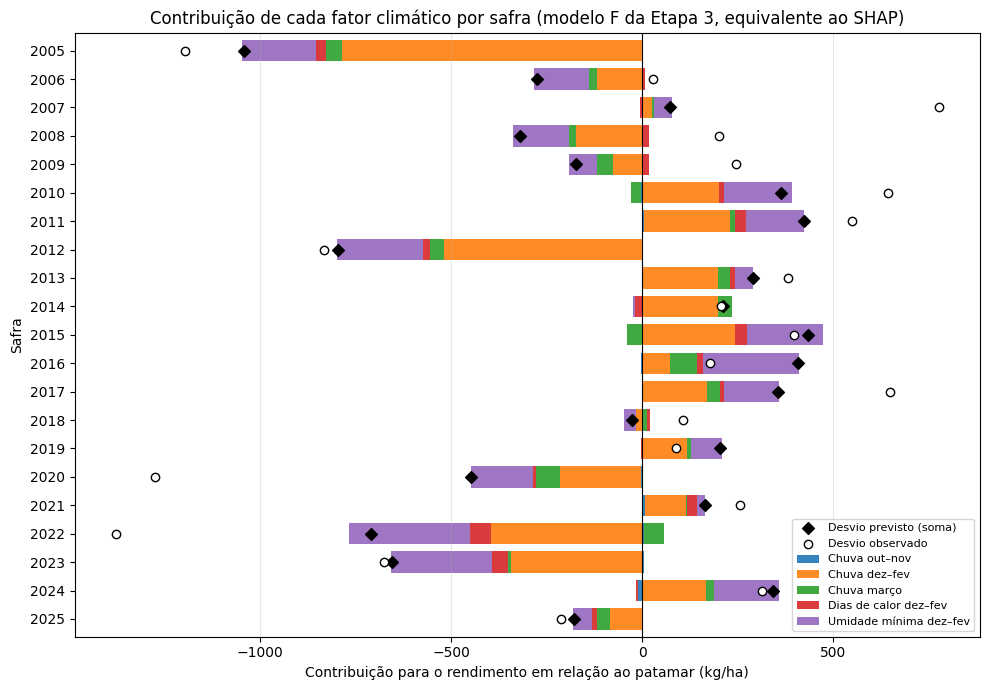

Importância média (média do |contribuição|, kg/ha):
Chuva dez–fev            250.00
Umidade mínima dez–fev   167.00
Chuva março               37.00
Dias de calor dez–fev     36.00
Chuva out–nov              4.00


,Chuva out–nov,Chuva dez–fev,Chuva março,Dias de calor dez–fev,Umidade mínima dez–fev,Desvio previsto,Desvio observado
ano_safra,,,,,,,
2012,3.00,-517.00,-38.00,-18.00,-225.00,-796.00,-832.00
2020,-3.00,-214.00,-60.00,-9.00,-163.00,-448.00,"-1,275.00"
2021,6.00,107.00,5.00,25.00,21.00,164.00,257.00
2022,4.00,-395.00,54.00,-57.00,-315.00,-709.00,"-1,377.00"
2023,5.00,-343.00,-9.00,-39.00,-266.00,-653.00,-676.00
2024,-11.00,167.00,20.00,-5.00,171.00,342.00,313.00
2025,3.00,-85.00,-34.00,-13.00,-49.00,-179.00,-213.00


In [12]:
coef = pd.Series(ols_final.coef_, index=FEAT_OLS)
contrib = completa[FEAT_OLS].sub(completa[FEAT_OLS].mean()).mul(coef)
FATORES = {"Chuva out–nov": ["chuva_out_nov_100"],
           "Chuva dez–fev": ["chuva_dez_fev_c100", "chuva_dez_fev_c100_2"],
           "Chuva março": ["chuva_mar_100"],
           "Dias de calor dez–fev": ["dias_calor_dez_fev"],
           "Umidade mínima dez–fev": ["urmin_dez_fev"]}
contrib = pd.DataFrame({f: contrib[cols].sum(axis=1) for f, cols in FATORES.items()})

por_safra_contrib = contrib.groupby(completa["ano_safra"]).mean()
por_safra_contrib["Desvio previsto"] = por_safra_contrib[list(FATORES)].sum(axis=1)
por_safra_contrib["Desvio observado"] = ((desvio_final - desvio_final.mean())
                                         .groupby(completa["ano_safra"]).mean())

fig, ax = plt.subplots(figsize=(10, 7))
por_safra_contrib[list(FATORES)].plot.barh(stacked=True, ax=ax, width=0.75, alpha=0.9)
y = np.arange(len(por_safra_contrib))
ax.scatter(por_safra_contrib["Desvio previsto"], y, marker="D", color="k", zorder=3,
           label="Desvio previsto (soma)")
ax.scatter(por_safra_contrib["Desvio observado"], y, marker="o", facecolor="white",
           edgecolor="k", zorder=3, label="Desvio observado")
ax.axvline(0, color="k", lw=0.8)
ax.invert_yaxis()
ax.set_xlabel("Contribuição para o rendimento em relação ao patamar (kg/ha)")
ax.set_ylabel("Safra")
ax.set_title("Contribuição de cada fator climático por safra (modelo F da Etapa 3, equivalente ao SHAP)")
ax.grid(axis="x", alpha=0.3)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

importancia_media = contrib.abs().mean().sort_values(ascending=False)
print("Importância média (média do |contribuição|, kg/ha):")
print(importancia_media.round(0).to_string())
por_safra_contrib.loc[[2012, 2020, 2021, 2022, 2023, 2024, 2025]].round(0)

## 12. Erro por região (mesorregiões do IBGE)

A metodologia previa métricas por região. Os municípios foram agrupados nas sete
mesorregiões geográficas do IBGE (tabela em `dataset/raw/ibge_municipios_rs_regioes.csv`,
obtida da API de localidades do IBGE). O erro relativo (MAE %) divide o erro absoluto
médio pelo rendimento médio observado da região, para comparar regiões com níveis de
produtividade diferentes. Os resultados são do modelo final nas duas validações.

Deixa uma safra de fora (2008–2025):


,linhas,municípios,rendimento médio (kg/ha),MAE (kg/ha),viés (kg/ha),MAE %
mesorregiao,,,,,,
Noroeste,2796,216,2708,504,-8,18.6%
Centro Oriental,526,53,2589,518,-3,20.0%
Metropolitana de Porto Alegre,467,60,2365,558,+188,23.6%
Nordeste,462,44,2994,533,+149,17.8%
Centro Ocidental,355,31,2337,536,+171,22.9%
Sudeste,269,25,2170,590,+55,27.2%
Sudoeste,250,19,1988,568,-217,28.6%


Corte temporal (teste 2021–2025):


,linhas,municípios,rendimento médio (kg/ha),MAE (kg/ha),viés (kg/ha),MAE %
mesorregiao,,,,,,
Noroeste,806,216,2622,617,+298,23.5%
Nordeste,189,43,2897,654,+231,22.6%
Centro Oriental,174,52,2432,496,+42,20.4%
Metropolitana de Porto Alegre,158,55,2317,604,+154,26.1%
Centro Ocidental,101,31,1819,616,+374,33.9%
Sudeste,90,25,2325,612,+34,26.3%
Sudoeste,73,19,1771,475,+39,26.8%


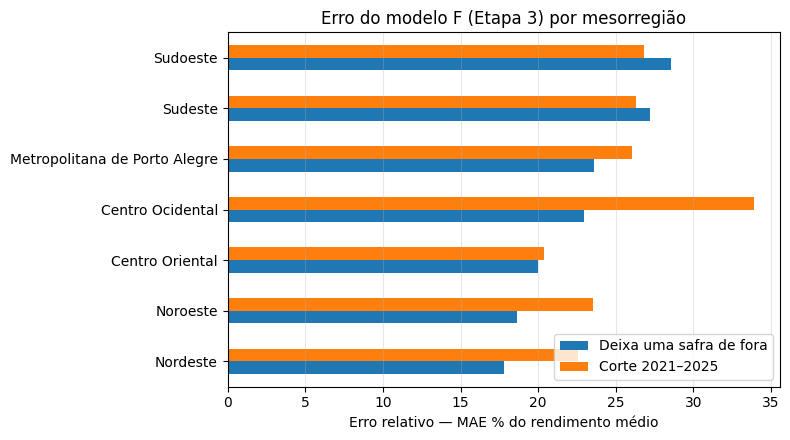

In [13]:
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")


def erro_por_grupo(dados, previsao, grupo):
    d = dados.assign(previsto=previsao, erro=previsao - dados[ALVO])
    g = d.groupby(grupo)
    t = pd.DataFrame({
        "linhas": g.size(),
        "municípios": g["codigo_ibge_municipio"].nunique(),
        "rendimento médio (kg/ha)": g[ALVO].mean(),
        "MAE (kg/ha)": g["erro"].apply(lambda e: e.abs().mean()),
        "viés (kg/ha)": g["erro"].mean(),
    })
    t["MAE %"] = t["MAE (kg/ha)"] / t["rendimento médio (kg/ha)"]
    return t


reg_corte = erro_por_grupo(teste.merge(regioes, on="codigo_ibge_municipio", how="left"),
                           prev_corte[chave_final], "mesorregiao")
reg_loyo = erro_por_grupo(loyo.merge(regioes, on="codigo_ibge_municipio", how="left"),
                          prev_loyo[chave_final], "mesorregiao")
FORMATO_REG = {"rendimento médio (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}",
               "viés (kg/ha)": "{:+.0f}", "MAE %": "{:.1%}"}
print("Deixa uma safra de fora (2008–2025):")
display(reg_loyo.sort_values("linhas", ascending=False).style.format(FORMATO_REG))
print("Corte temporal (teste 2021–2025):")
display(reg_corte.sort_values("linhas", ascending=False).style.format(FORMATO_REG))

ordem = reg_loyo.sort_values("MAE %").index
ax = pd.DataFrame({"Deixa uma safra de fora": reg_loyo["MAE %"],
                   "Corte 2021–2025": reg_corte["MAE %"]}).loc[ordem].mul(100).plot.barh(figsize=(8, 4.5))
ax.set_xlabel("Erro relativo — MAE % do rendimento médio")
ax.set_ylabel("")
ax.set_title("Erro do modelo F (Etapa 3) por mesorregião")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 13. Erro por município

Com a validação "deixa uma safra de fora", cada município tem várias safras previstas
sem ter sido visto. Considerando os municípios com pelo menos 8 safras avaliadas,
calculamos o erro relativo (MAE %) de cada um.

Municípios com >= 8 safras avaliadas: 375
Distribuição do MAE % por município:
mean    20.9%
std      6.3%
min      7.3%
10%     13.4%
25%     16.2%
50%     19.9%
75%     24.6%
90%     29.8%
max     41.7%


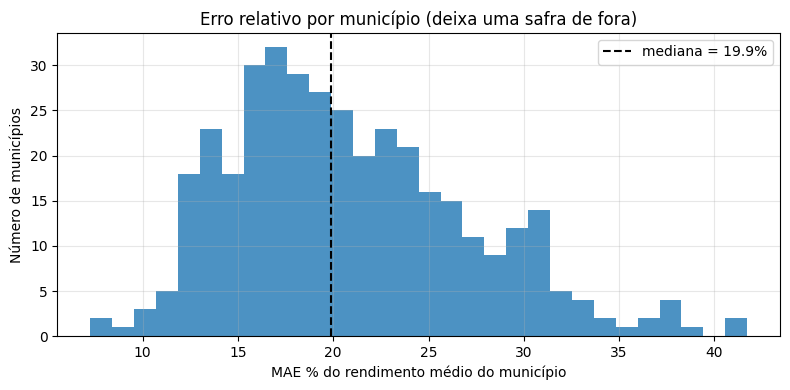

Correlação entre rendimento médio e MAE % dos municípios: -0.62

5 municípios com menor erro relativo:


,municipio,mesorregiao,linhas,rendimento médio (kg/ha),MAE (kg/ha),MAE %
codigo_ibge_municipio,,,,,,
4312617,Muitos Capões - RS,Nordeste,16,3300,239,7.3%
4309050,Glorinha - RS,Metropolitana de Porto Alegre,9,2629,213,8.1%
4312708,Nonoai - RS,Noroeste,14,3054,288,9.4%
4314779,Pontão - RS,Noroeste,17,2858,275,9.6%
4311304,Lagoa Vermelha - RS,Nordeste,16,3106,331,10.7%


5 municípios com maior erro relativo:


,municipio,mesorregiao,linhas,rendimento médio (kg/ha),MAE (kg/ha),MAE %
codigo_ibge_municipio,,,,,,
4317103,Sant'Ana do Livramento - RS,Sudoeste,13,1869,780,41.7%
4322400,Uruguaiana - RS,Sudoeste,13,2307,953,41.3%
4315305,Quaraí - RS,Sudoeste,9,1431,548,38.3%
4312427,Mormaço - RS,Noroeste,12,2109,803,38.1%
4304358,Candiota - RS,Sudeste,17,1826,694,38.0%


In [14]:
mun = erro_por_grupo(loyo.merge(regioes, on="codigo_ibge_municipio", how="left"),
                     prev_loyo[chave_final], "codigo_ibge_municipio").drop(columns="municípios")
mun = mun[mun["linhas"] >= 8].join(
    painel.drop_duplicates("codigo_ibge_municipio").set_index("codigo_ibge_municipio")["municipio"]
).join(regioes.set_index("codigo_ibge_municipio"))
print(f"Municípios com >= 8 safras avaliadas: {len(mun)}")
print("Distribuição do MAE % por município:")
print(mun["MAE %"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).map("{:.1%}".format)
      .drop("count").to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mun["MAE %"] * 100, bins=30, color="tab:blue", alpha=0.8)
ax.axvline(mun["MAE %"].median() * 100, color="k", ls="--",
           label=f"mediana = {mun['MAE %'].median():.1%}")
ax.set_xlabel("MAE % do rendimento médio do município")
ax.set_ylabel("Número de municípios")
ax.set_title("Erro relativo por município (deixa uma safra de fora)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

colunas = ["municipio", "mesorregiao", "linhas", "rendimento médio (kg/ha)", "MAE (kg/ha)", "MAE %"]
print("Correlação entre rendimento médio e MAE % dos municípios:",
      f"{mun['rendimento médio (kg/ha)'].corr(mun['MAE %']):+.2f}")
formato_mun = {k: v for k, v in FORMATO_REG.items() if k in colunas}
print("\n5 municípios com menor erro relativo:")
display(mun.nsmallest(5, "MAE %")[colunas].style.format(formato_mun))
print("5 municípios com maior erro relativo:")
display(mun.nlargest(5, "MAE %")[colunas].style.format(formato_mun))

## 14. Conclusões da Etapa 3 e modelo final

**Modelo final: patamar pela média móvel dos últimos 5 anos do município + OLS reduzida
sobre o desvio.** Teve o menor RMSE médio nas duas validações:

| Validação | RMSE (kg/ha) | MAE (kg/ha) | R² | Viés (kg/ha) |
|---|---|---|---|---|
| Corte temporal (teste 2021–2025) | 767 | 600 | 0,26 | +226 |
| Deixa uma safra de fora (2008–2025) | 689 | 523 | 0,25 | +30 |

Na média estadual por safra, o erro é de ~270–310 kg/ha (~11–12% do rendimento médio),
com correlação de ~0,7 com o observado.

**0. O modelo final supera as duas linhas de base previstas no artigo, nas duas
validações.**

| RMSE (kg/ha) | Corte 2021–2025 | Deixa uma safra de fora |
|---|---|---|
| Linha de base: safra anterior | 1.276 | 979 |
| Linha de base: média histórica | 861 | 877 |
| **Modelo final** | **767 (−11%)** | **689 (−21%)** |

(percentuais em relação à média histórica, a melhor das duas linhas de base). Repetir o
rendimento da safra anterior é a pior estratégia: uma seca ou um recorde se propagam
para a previsão seguinte. A média histórica de todas as safras anteriores fica para trás
na validação "deixa uma safra de fora" porque não acompanha o crescimento da
produtividade (viés de −451 kg/ha).

**1. O patamar importa, e a média móvel funcionou melhor.** A reta com todo o histórico
continua projetando ~3.000 kg/ha para 2021–2025 (viés de +540 kg/ha sem clima), porque
o crescimento forte de 2000–2019 não se manteve nas safras recentes. A média móvel de 5
anos acompanha o patamar recente sem extrapolar. A reta dos últimos 10 anos tem o menor
viés no corte temporal, mas oscila muito: ela "mergulha" depois de anos ruins (prevê
~2.200 kg/ha para 2024–2025) e foi a pior na validação "deixa uma safra de fora". A média
olímpica ficou no meio do caminho: descartar extremos protege de uma safra isolada, mas
não de uma sequência de secas.

**2. O clima acrescenta valor sobre qualquer patamar.** Somar o clima (OLS reduzida)
reduziu o RMSE em 13–16% em quase todos os cenários (só 5% com a reta de 10 anos na
validação "deixa uma safra de fora") e levou o R² de ~0 (só patamar) para 0,05–0,26.
Quem distingue uma safra boa de uma ruim é o clima de dez–fev.

**3. A OLS reduzida superou o Gradient Boosting.** Com uma variável por fenômeno, a OLS
foi melhor ou igual às árvores em todos os cenários. As árvores continuam
limitadas pelos extremos do treino (não preveem secas mais fortes do que as que já
viram), e o ganho delas com interações não compensou isso.

**4. Os coeficientes agora são coerentes e podem ir para o artigo** (desvio em relação
ao patamar do município):
- **chuva em dez–fev:** +208 kg/ha a cada 100 mm acima da média (~417 mm), com ganho
  decrescente (termo quadrático −41): falta de chuva no período crítico é o fator mais
  forte;
- **umidade mínima em dez–fev:** +30 kg/ha por ponto percentual (ar seco = estresse
  hídrico);
- **chuva em março:** +59 kg/ha a cada 100 mm;
- **dias de calor em dez–fev:** −2,7 kg/ha por dia com máxima ≥ 32 °C (efeito pequeno
  depois de considerar a umidade, que já capta boa parte do estresse);
- **chuva em out–nov:** sem efeito significativo.

A maior correlação entre as variáveis do modelo é 0,63, então não há mais a
colinearidade forte que invertia sinais na Etapa 2.

**5. Correção do resultado da Etapa 2.** O R² de 0,44 na validação "deixa uma safra de
fora" da Etapa 2 era otimista, porque o patamar usava safras futuras. Com patamar
calculado só com o passado, o valor realista é ~0,25. **Para o artigo, usar os
números desta etapa.**

**6. Quais fatores mais pesam (seção 11, equivalente ao SHAP).** Em média, a chuva de
dez–fev move a previsão em ~250 kg/ha e a umidade mínima de dez–fev em ~170 kg/ha. Chuva
de março e dias de calor pesam ~35 kg/ha cada, e a chuva de out–nov é desprezível. O
período de floração e enchimento de grãos concentra praticamente todo o efeito do clima.
A decomposição explica bem as safras de 2012 (desvio previsto −796 × observado −832
kg/ha), 2023 (−653 × −676) e 2024 (+342 × +313).

**7. Limite que permanece: as secas mais severas.** Na decomposição da seção 11 (modelo
ajustado com todas as safras, inclusive as próprias 2020 e 2022), o modelo explica só
cerca de metade dessas quebras (desvio previsto −448 e −709 kg/ha; observado −1.275 e
−1.377). **Fora da amostra é pior:** quando 2020 e 2022 são previstas sem terem sido
vistas, o modelo antecipa só ~4% e ~25% da quebra, respectivamente (ver seção 9 de
`modelagem_etapa4.ipynb`). O viés do corte temporal (+226 kg/ha) vem quase todo de
2022 (previsto ~2.750 kg/ha, observado ~1.680). Isso indica que a perda cresce mais
rápido que o modelo linear supõe quando a seca passa de um limite. Nas demais safras de
teste, a média estadual ficou a menos de ~300 kg/ha do observado (2021, 2024 e 2025 a
menos de ~110).

**8. Erro por região (seção 12).** O menor erro relativo está no **Noroeste** (18,6% na
validação "deixa uma safra de fora"), principal região produtora e com mais da metade
das linhas da base, e no **Nordeste** (17,8%). Os maiores estão no **Sudoeste** (28,6%) e
no **Sudeste** (27,2%), regiões com produtividade média menor. Uma hipótese, que estes
dados não testam, é que lá a soja tenha se expandido mais recentemente (inclusive em
terras baixas em rotação com arroz), com menos histórico por município e maior
sensibilidade ao clima. Vale verificar na literatura antes de afirmar no artigo.

**9. Erro por município (seção 13).** Entre os 375 municípios com pelo menos 8 safras
avaliadas, o erro relativo mediano é de ~20% (metade dos municípios entre 16% e 25%).
Municípios de produtividade mais alta têm erro relativo menor (correlação −0,62). Os
maiores erros estão na fronteira oeste (Sant'Ana do Livramento, Uruguaiana, Quaraí,
~40%), e os menores no Planalto (Muitos Capões, Nonoai, Pontão, Lagoa Vermelha, 7–11%).

**Próximos passos possíveis:**
- **Artigo:** descrever o modelo final, as duas validações, a comparação com as linhas
  de base, os coeficientes (seção 10), a contribuição dos fatores (seção 11) e o erro
  por região (seção 12). Os resultados das Etapas 1 e 2 entram como evolução da
  metodologia.
- **Melhorar a previsão de secas extremas:** incluir um indicador de déficit hídrico
  (chuva − evapotranspiração) em dez–fev e testar um efeito de limite (por exemplo,
  perda adicional quando a umidade mínima fica abaixo de ~40%), já que o modelo
  subestima a quebra justamente nas secas mais fortes.
- **Cobertura:** a base desta etapa usa ~5.260 das 10.540 linhas com rendimento, por
  falta de clima do INMET. Uma fonte em grade (NASA POWER) poderia incluir os demais
  municípios.